# Belgian electricity demand: can a model beat Elia's day-ahead forecast?

**Elia** runs the Belgian high-voltage grid. Every morning it forecasts tomorrow's electricity demand, 15 minutes at a
time, so power plants can be scheduled. A good forecast saves money and keeps the grid stable.

**Data (open, no key):** Elia's measured grid load every 15 min since 2015, with Elia's own day-ahead forecast
next to it, plus hourly weather for central Belgium from Open-Meteo.

**The task:** at the end of day D−1, predict the load of every hour of day D.

**The benchmark:** Elia's day-ahead forecast, made by professionals with far more inputs than we have.

Runs on a laptop CPU in a few minutes. In Colab: upload `mlkit.py`, `elia_load.parquet` and `weather.parquet`.

In [1]:
import os, sys, time, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
for p in [Path.cwd(), *Path.cwd().parents]:
    if (p / "src" / "mlkit.py").exists():
        sys.path.insert(0, str(p / "src")); break
import mlkit
if mlkit.IN_COLAB:
    os.system("pip -q install lightgbm holidays")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
import holidays
import torch
from torch import nn

DATA, OUT = mlkit.paths("grid_load")
mlkit.colab_upload(DATA, ["elia_load.parquet", "weather.parquet"])
plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
torch.manual_seed(0); np.random.seed(0)
TZ = "Europe/Brussels"


def save(name):
    mlkit.save_fig(OUT, name)

## 1. Load and clean
15-minute values are averaged to hours (the unit of the task). Future rows (Elia already publishes forecasts for
the coming days, with no measured load yet) are dropped.

In [2]:
raw = pd.read_parquet(DATA / "elia_load.parquet")
raw["hour"] = raw["datetime"].dt.floor("h")
h = (raw.groupby("hour")[["totalload", "dayaheadforecast"]].mean()
     .rename(columns={"totalload": "load", "dayaheadforecast": "elia_da"}))
h = h[h["load"].notna()]
print(f"{len(h):,} hours, {h.index.min():%d %b %Y} -> {h.index.max():%d %b %Y}")
gaps = pd.date_range(h.index.min(), h.index.max(), freq="h").difference(h.index)
print(f"missing hours: {len(gaps)}")
h.describe().round(0)

103,618 hours, 31 Dec 2014 -> 27 Oct 2026
missing hours: 1


,load,elia_da
count,103618.0,103618.0
mean,9550.0,9536.0
std,1389.0,1359.0
min,5930.0,6091.0
25%,8463.0,8468.0
50%,9529.0,9519.0
75%,10572.0,10543.0
max,13670.0,13629.0


In [3]:
w = pd.read_parquet(DATA / "weather.parquet").set_index("hour")
h = h.join(w, how="left")
local = h.index.tz_convert(TZ)
h["hod"], h["dow"], h["month"], h["year"] = local.hour, local.dayofweek, local.month, local.year
h["doy"] = local.dayofyear
be = holidays.Belgium(years=range(2015, 2028))
h["holiday"] = pd.Series(local.date, index=h.index).map(lambda d: d in be).astype(int)
print("weather coverage:", h["temperature_2m"].notna().mean().round(3))

weather coverage: 0.999


## 2. What drives demand?

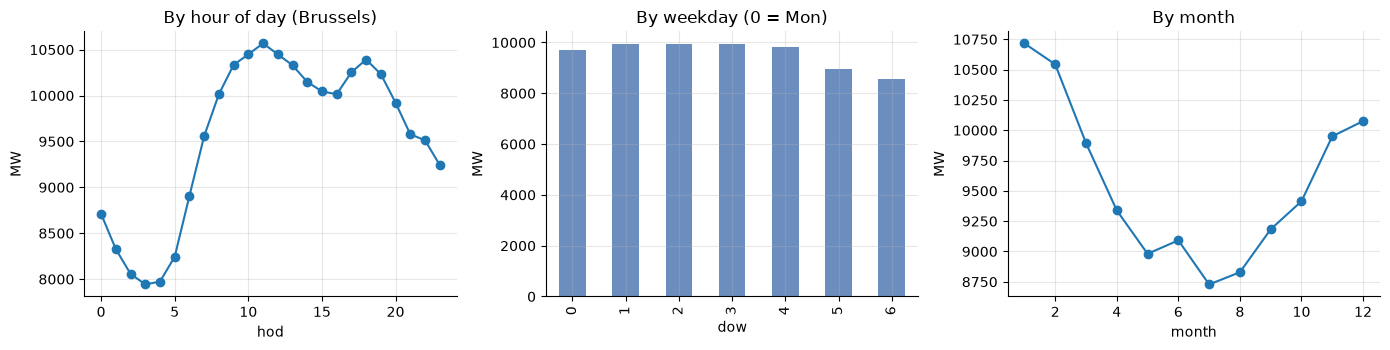

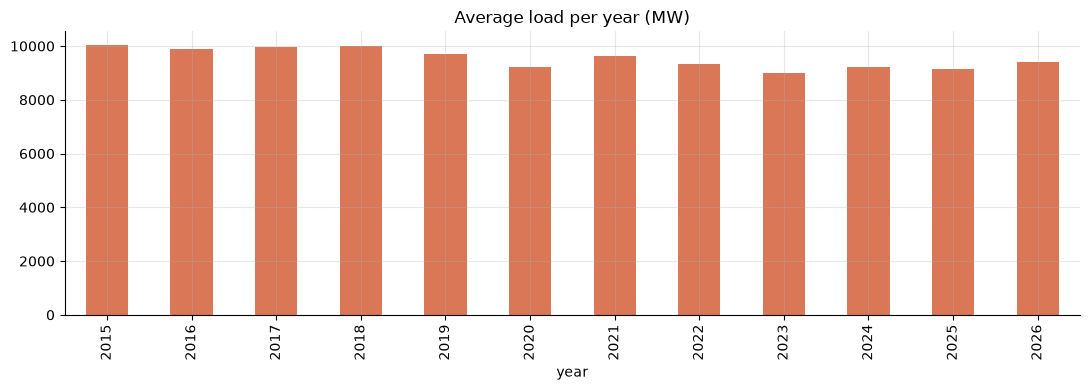

year
2015    10045.0
2016     9891.0
2017     9970.0
2018     9987.0
2019     9697.0
2020     9237.0
2021     9641.0
2022     9330.0
2023     9007.0
2024     9218.0
2025     9155.0
2026     9396.0


In [4]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
h.groupby("hod")["load"].mean().plot(ax=ax[0], marker="o", title="By hour of day (Brussels)")
h.groupby("dow")["load"].mean().plot.bar(ax=ax[1], color="#6c8ebf", title="By weekday (0 = Mon)")
h.groupby("month")["load"].mean().plot(ax=ax[2], marker="o", title="By month")
for a in ax: a.set_ylabel("MW")
save("01_patterns")

yearly = h.groupby("year")["load"].mean()
yearly.plot.bar(color="#d97757", title="Average load per year (MW)"); save("02_years")
print(yearly.round(0).to_string())

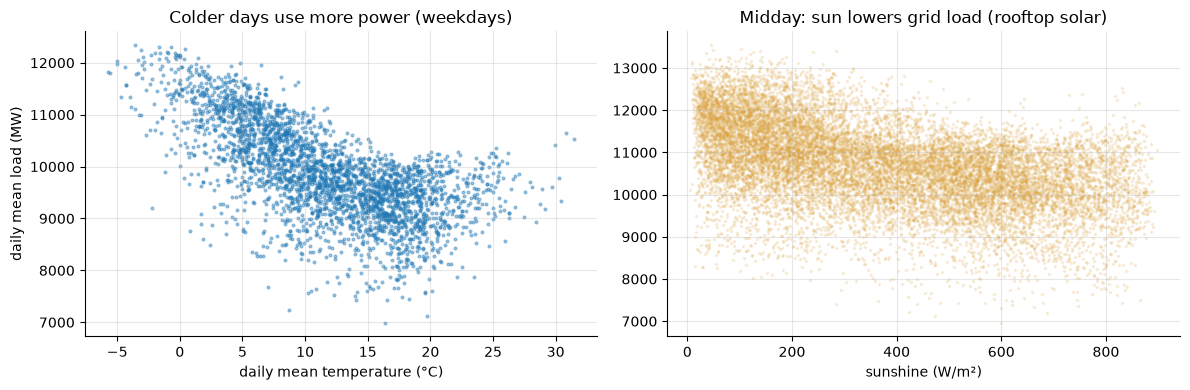

correlation, daily load vs temperature: -0.66
correlation, midday load vs sunshine:   -0.48


In [5]:
daily = h.resample("D").agg({"load": "mean", "temperature_2m": "mean", "shortwave_radiation": "mean", "dow": "first"})
wk = daily[daily["dow"] < 5]
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].scatter(wk["temperature_2m"], wk["load"], s=4, alpha=0.4); ax[0].set_xlabel("daily mean temperature (°C)")
ax[0].set_ylabel("daily mean load (MW)"); ax[0].set_title("Colder days use more power (weekdays)")
mid = h[(h["hod"] >= 11) & (h["hod"] <= 15) & (h["dow"] < 5)]
ax[1].scatter(mid["shortwave_radiation"], mid["load"], s=2, alpha=0.15, color="#e0a33a")
ax[1].set_xlabel("sunshine (W/m²)"); ax[1].set_title("Midday: sun lowers grid load (rooftop solar)")
save("03_weather")
print("correlation, daily load vs temperature:", round(wk["load"].corr(wk["temperature_2m"]), 2))
print("correlation, midday load vs sunshine:  ", round(mid["load"].corr(mid["shortwave_radiation"]), 2))

## 3. Features: only what is known when the forecast is made

| Feature | Known at the end of D−1? |
|---|---|
| hour, weekday, month, day of year, holiday | yes, the calendar |
| load 2 days earlier, same hour | yes (Elia's measured load arrives with about a day of delay, so 1 day back is not safe) |
| load 7 days earlier, same hour; mean of the same hour over days 2–7 back | yes |
| weather of day D | **in real life only as a forecast.** Here we use the *measured* weather: an upper bound on what a weather forecast could give. The model *without* weather shows the floor. |

**Split by time:** train 2015–2022, validation 2023 (for early stopping), **test = 2024 until now**, never seen.

In [6]:
for lag in [48, 72, 168]:
    h[f"load_lag{lag}"] = h["load"].shift(lag, freq="h").reindex(h.index)
h["load_mean_2_7d"] = sum(h["load"].shift(24 * d, freq="h").reindex(h.index) for d in range(2, 8)) / 6

CAL = ["hod", "dow", "month", "doy", "holiday"]
LAGS = ["load_lag48", "load_lag72", "load_lag168", "load_mean_2_7d"]
WEATHER = ["temperature_2m", "shortwave_radiation", "cloud_cover", "wind_speed_10m"]
FEATURES = CAL + LAGS + WEATHER

d = h.dropna(subset=["load_lag168"])
train, val, test = mlkit.time_split(d, d.index.to_series(), pd.Timestamp("2023-01-01", tz="UTC"),
                                    pd.Timestamp("2024-01-01", tz="UTC"))
test_w = test[test["temperature_2m"].notna()]  # weather archive ends a few days before today
print(f"train {len(train):,}  val {len(val):,}  test {len(test_w):,} hours "
      f"({test_w.index.min():%d %b %Y} -> {test_w.index.max():%d %b %Y})")

train 69,959  val 8,760  test 24,600 hours (01 Jan 2024 -> 21 Oct 2026)


## 4. Baselines

In [7]:
results = {}


def score(name, pred, rows=test_w):
    results[name] = {"mae_mw": mlkit.mae(rows["load"], pred), "mape_pct": mlkit.mape(rows["load"], pred)}
    print(f"{name:<45} MAE {results[name]['mae_mw']:6.0f} MW   MAPE {results[name]['mape_pct']:.2f}%")


score("Same hour last week", test_w["load_lag168"])
score("Mean of same hour, 2-7 days back", test_w["load_mean_2_7d"])
score("Elia day-ahead forecast (the professionals)", test_w["elia_da"])

Same hour last week                           MAE    442 MW   MAPE 4.75%
Mean of same hour, 2-7 days back              MAE    581 MW   MAPE 6.33%
Elia day-ahead forecast (the professionals)   MAE    256 MW   MAPE 2.75%


## 5. LightGBM

LightGBM (calendar + lags + weather)          MAE    264 MW   MAPE 2.89%


LightGBM without weather                      MAE    288 MW   MAPE 3.14%
(63s)


LightGBM + Elia's forecast as input           MAE    235 MW   MAPE 2.55%


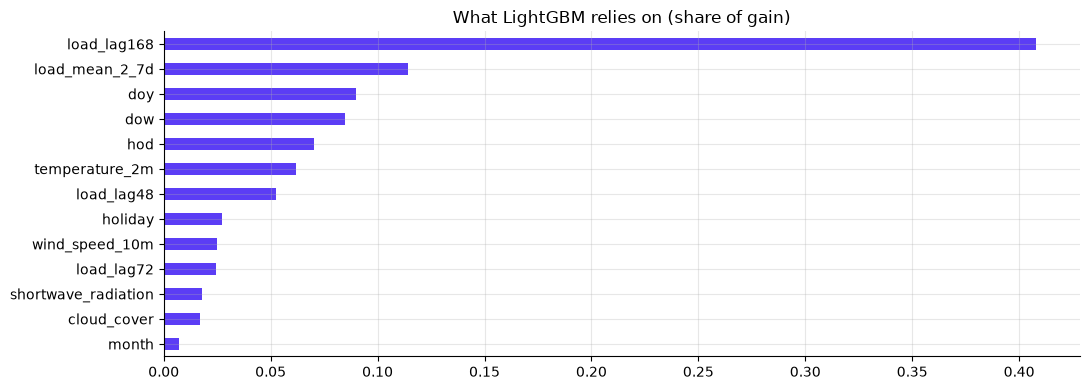

In [8]:
def fit_lgb(features):
    m = lgb.LGBMRegressor(objective="l1", n_estimators=5000, learning_rate=0.03, num_leaves=63,
                          min_child_samples=40, subsample=0.8, subsample_freq=1, colsample_bytree=0.8, verbose=-1)
    m.fit(train[features], train["load"], eval_set=[(val[features], val["load"])],
          callbacks=[lgb.early_stopping(200, verbose=False)])
    return m


t = time.time()
gbm = fit_lgb(FEATURES)
score("LightGBM (calendar + lags + weather)", gbm.predict(test_w[FEATURES]))
no_w = [f for f in FEATURES if f not in WEATHER]
gbm_nw = fit_lgb(no_w)
score("LightGBM without weather", gbm_nw.predict(test_w[no_w]))
print(f"({time.time() - t:.0f}s)")

# Elia publishes its day-ahead forecast the day before, so a model may use it as an input: can we correct it?
with_elia = FEATURES + ["elia_da"]
gbm_elia = fit_lgb(with_elia)
score("LightGBM + Elia's forecast as input", gbm_elia.predict(test_w[with_elia]))

imp = pd.Series(gbm.booster_.feature_importance("gain"), index=FEATURES).sort_values()
(imp / imp.sum()).plot.barh(color="#5b3df5", title="What LightGBM relies on (share of gain)"); save("04_importance")

## 6. Neural network
Same features. Hour, weekday and month get learned embeddings; numbers are standardised; two hidden layers;
L1 loss; early stopping on 2023.

Neural network (embeddings + MLP)             MAE    268 MW   MAPE 2.92%
16 epochs, 72s


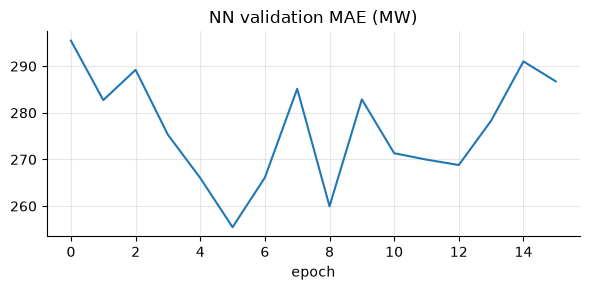

In [9]:
CATS = {"hod": 24, "dow": 7, "month": 13}
NUMS = ["doy", "holiday"] + LAGS + WEATHER
mu, sd = train[NUMS].mean(), train[NUMS].std()
y_mu, y_sd = train["load"].mean(), train["load"].std()


def tensors(df):
    xc = torch.tensor(df[list(CATS)].values.astype(int))
    xn = torch.tensor(((df[NUMS] - mu) / sd).fillna(0).values, dtype=torch.float32)
    y = torch.tensor(((df["load"] - y_mu) / y_sd).values, dtype=torch.float32)
    return xc, xn, y


class Net(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.ModuleList([nn.Embedding(n, 6) for n in CATS.values()])
        self.mlp = nn.Sequential(nn.Linear(6 * len(CATS) + len(NUMS), 256), nn.ReLU(), nn.Dropout(0.1),
                                 nn.Linear(256, 128), nn.ReLU(), nn.Linear(128, 1))

    def forward(self, xc, xn):
        return self.mlp(torch.cat([e(xc[:, i]) for i, e in enumerate(self.emb)] + [xn], 1)).squeeze(1)


tr, va, te = tensors(train), tensors(val), tensors(test_w)
net, loss_fn = Net(), nn.L1Loss()
opt = torch.optim.AdamW(net.parameters(), lr=1e-3, weight_decay=1e-5)
best, state, patience, hist = 1e9, None, 0, []
t = time.time()
for epoch in range(200):
    net.train()
    for idx in torch.randperm(len(tr[2])).split(1024):
        opt.zero_grad(); loss_fn(net(tr[0][idx], tr[1][idx]), tr[2][idx]).backward(); opt.step()
    net.eval()
    with torch.no_grad():
        v = loss_fn(net(va[0], va[1]), va[2]).item()
    hist.append(v * y_sd)
    if v < best - 1e-4:
        best, state, patience = v, {k: x.clone() for k, x in net.state_dict().items()}, 0
    elif (patience := patience + 1) >= 10:
        break
net.load_state_dict(state); net.eval()
with torch.no_grad():
    nn_pred = net(te[0], te[1]).numpy() * y_sd + y_mu
score("Neural network (embeddings + MLP)", nn_pred)
print(f"{len(hist)} epochs, {time.time() - t:.0f}s")
plt.figure(figsize=(6, 3)); plt.plot(hist); plt.title("NN validation MAE (MW)"); plt.xlabel("epoch"); save("05_nn_training")

## 7. Results on the test period (2024 until now)

                                              mae_mw  mape_pct
LightGBM + Elia's forecast as input          234.788     2.548
Elia day-ahead forecast (the professionals)  256.056     2.751
LightGBM (calendar + lags + weather)         264.438     2.895
Neural network (embeddings + MLP)            267.973     2.923
LightGBM without weather                     287.856     3.136
Same hour last week                          441.787     4.748
Mean of same hour, 2-7 days back             580.994     6.332


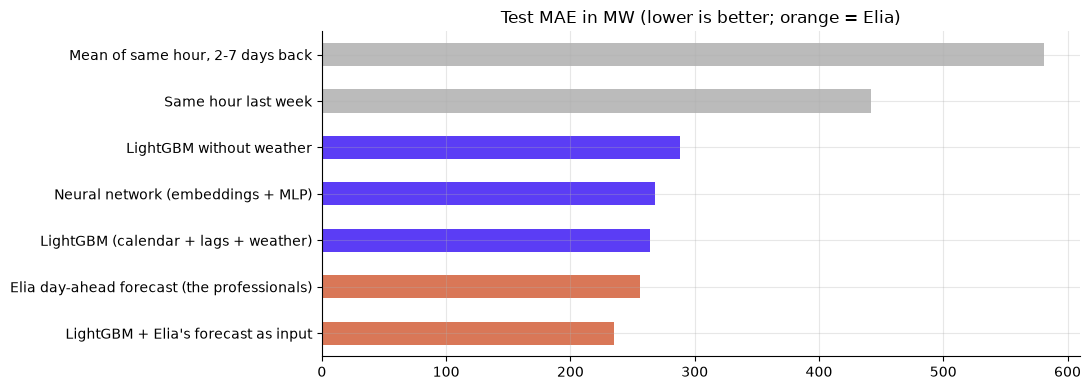

In [10]:
res = mlkit.save_metrics(OUT, results)
colors = ["#d97757" if "Elia" in k else "#5b3df5" if ("LightGBM" in k or "Neural" in k) else "#bbbbbb" for k in res.index]
res["mae_mw"].plot.barh(color=colors, title="Test MAE in MW (lower is better; orange = Elia)"); save("06_results")

## 8. Where and when do we lose to Elia (or beat it)?

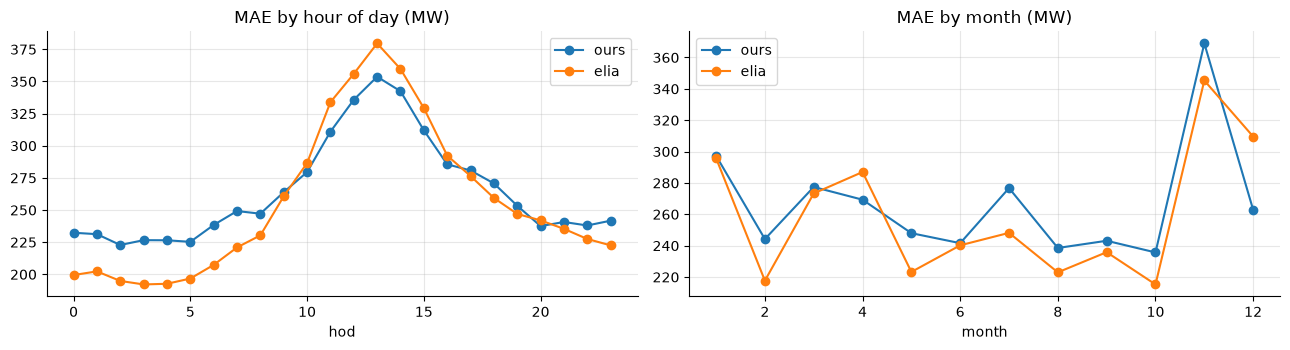

MAE on holidays vs normal days (MW):
           ours   elia
holiday              
0        265.0  254.0
1        242.0  321.0


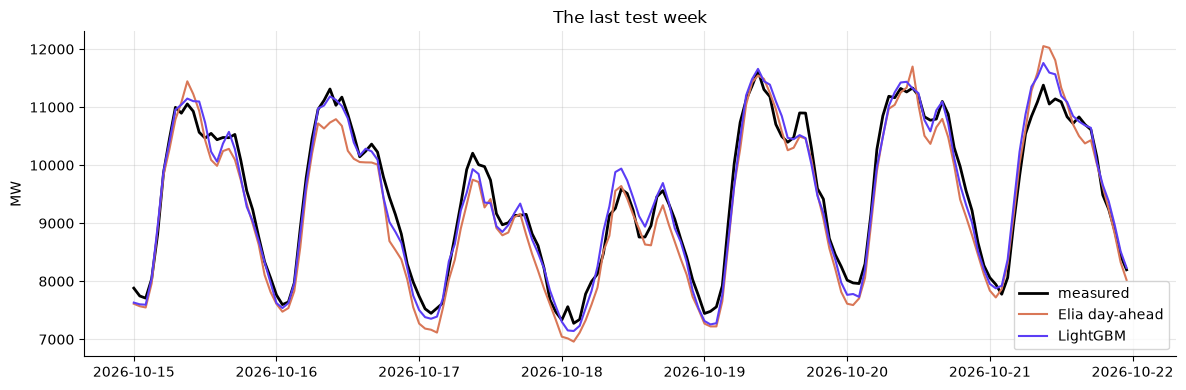

In [11]:
test_w = test_w.assign(ours=gbm.predict(test_w[FEATURES]))
err = pd.DataFrame({"ours": (test_w["ours"] - test_w["load"]).abs(), "elia": (test_w["elia_da"] - test_w["load"]).abs(),
                    "hod": test_w["hod"], "month": test_w["month"], "holiday": test_w["holiday"]})
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
err.groupby("hod")[["ours", "elia"]].mean().plot(ax=ax[0], marker="o", title="MAE by hour of day (MW)")
err.groupby("month")[["ours", "elia"]].mean().plot(ax=ax[1], marker="o", title="MAE by month (MW)")
save("07_error_breakdown")
print("MAE on holidays vs normal days (MW):\n", err.groupby("holiday")[["ours", "elia"]].mean().round(0).to_string())

week = test_w.loc[test_w.index[-24 * 7:]]
plt.figure(figsize=(12, 4))
plt.plot(week.index, week["load"], color="k", lw=2, label="measured")
plt.plot(week.index, week["elia_da"], color="#d97757", label="Elia day-ahead")
plt.plot(week.index, week["ours"], color="#5b3df5", label="LightGBM")
plt.legend(); plt.title("The last test week"); plt.ylabel("MW"); save("08_last_week")

## 9. What we found (run of 27 Oct 2026)

**Data.** 103,618 hours of Belgian grid load (Jan 2015 to Oct 2026), 1 missing hour; weather for 99.9% of hours.
Demand fell from ~10,000 MW (2015) to ~9,000 MW (2023): efficiency, the 2020 lockdowns, the 2022 energy crisis and
rooftop solar, which the grid does not see. Colder days use more power (r = −0.66); sunny middays use less (r = −0.48).

**Test: 1 Jan 2024 to 21 Oct 2026, 24,600 hours never seen in training.**

| Model | MAE (MW) | MAPE |
|---|---|---|
| Mean of same hour, 2-7 days back | 581 | 6.33% |
| Same hour last week | 442 | 4.75% |
| LightGBM without weather | 288 | 3.14% |
| Neural network (embeddings + MLP) | 268 | 2.92% |
| LightGBM (calendar + lags + weather) | 264 | 2.90% |
| **Elia's own day-ahead forecast** | **256** | **2.75%** |
| **LightGBM + Elia's forecast as input** | **235** | **2.55%** |

- From open data alone, LightGBM gets within 0.15 points of Elia's professional forecast; the neural network is
  close behind (trees still win on tabular data).
- **On public holidays our model beats Elia** (242 vs 321 MW): Elia's forecast struggles on holidays, the calendar
  feature handles them.
- **Using Elia's forecast as an input and learning its errors beats Elia by 8%** (235 vs 256 MW). This is the
  most useful result: a correction layer on top of an existing forecast.
- Weather is worth about 24 MW (288 → 264).

**Caveats, said plainly.**
- The weather features are the *measured* weather of day D; in real life only a weather forecast exists the day
  before. So the scores with weather are a best case. The no-weather model (288 MW) is the floor. The honest next
  step is Open-Meteo's archive of past *forecasts* (available since 2022).
- Elia's measured load arrives with about a day of delay, so the newest load feature is 2 days old: built in.

**Next.** Historical weather *forecasts* instead of measured weather; probabilistic forecasts (Elia also publishes
10%–90% bands); a peak alert on top.
